# EDA

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
planes = pd.read_excel("../../data/flight_price_train_cleaned.xlsx")

planes["Date_of_Journey"] = pd.to_datetime(planes["Date_of_Journey"])
planes["Dep_Time"] = pd.to_datetime(planes["Dep_Time"])
planes["Arrival_Time"] = pd.to_datetime(planes["Arrival_Time"])

planes["Duration"] = planes["Duration"].astype(float)
planes["Price"] = planes["Price"].astype(float)

planes.dropna(inplace=True)


In [4]:
planes.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,2019-03-24 22:20:00,2019-03-24 01:10:00,170.0,non-stop,No info,3897.0
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,2019-05-01 05:50:00,2019-05-01 13:15:00,445.0,2 stops,No info,7662.0
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,2019-06-09 09:25:00,2019-06-09 04:25:00,1140.0,2 stops,No info,13882.0
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,2019-05-12 18:05:00,2019-05-12 23:30:00,325.0,1 stop,No info,6218.0
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,2019-03-01 16:50:00,2019-03-01 21:35:00,285.0,1 stop,No info,13302.0


In [5]:
planes["Destination"].value_counts(normalize=True)

Destination
Cochin       0.424640
Banglore     0.268770
Delhi        0.118424
New Delhi    0.087250
Hyderabad    0.065250
Kolkata      0.035667
Name: proportion, dtype: float64

In [6]:
planes["Source"].value_counts(normalize=True)

Source
Delhi       0.424640
Kolkata     0.268770
Banglore    0.205673
Mumbai      0.065250
Chennai     0.035667
Name: proportion, dtype: float64

In [7]:
planes["Destination"].value_counts()

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

In [8]:
pd.crosstab(planes["Source"], planes["Destination"])

Destination,Banglore,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
Source,,,,,,
Banglore,0,0,1265,0,0,932
Chennai,0,0,0,0,381,0
Delhi,0,4536,0,0,0,0
Kolkata,2871,0,0,0,0,0
Mumbai,0,0,0,697,0,0


In [9]:
planes["Route"].value_counts()

Route
DEL → BOM → COK          2376
BLR → DEL                1552
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
                         ... 
CCU → VTZ → BLR             1
CCU → IXZ → MAA → BLR       1
BOM → COK → MAA → HYD       1
BOM → CCU → HYD             1
BOM → BBI → HYD             1
Name: count, Length: 128, dtype: int64

In [10]:
pd.crosstab(planes["Source"], planes["Destination"], values=planes["Price"], aggfunc="median")

Destination,Banglore,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
Source,,,,,,
Banglore,NaN,NaN,4823.0,NaN,NaN,10898.5
Chennai,NaN,NaN,NaN,NaN,3850.0,NaN
Delhi,NaN,10262.0,NaN,NaN,NaN,NaN
Kolkata,9345.0,NaN,NaN,NaN,NaN,NaN
Mumbai,NaN,NaN,NaN,3342.0,NaN,NaN


In [11]:
planes.groupby(["Source", "Destination"])["Price"].median().reset_index()

,Source,Destination,Price
0,Banglore,Delhi,4823.0
1,Banglore,New Delhi,10898.5
2,Chennai,Kolkata,3850.0
3,Delhi,Cochin,10262.0
4,Kolkata,Banglore,9345.0
5,Mumbai,Hyderabad,3342.0


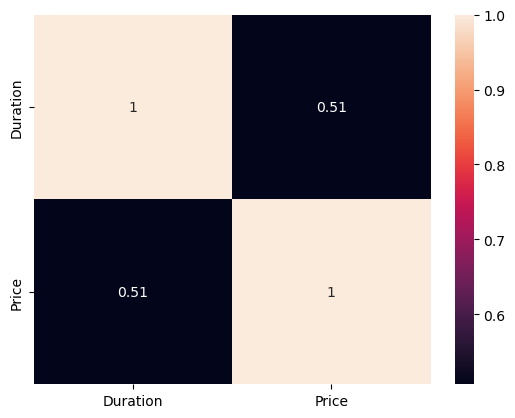

In [12]:
numeric_data = planes.select_dtypes("number")
sns.heatmap(numeric_data.corr(), annot=True)
plt.show()

In [13]:
planes["Total_Stops"].value_counts(
)

Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [14]:
planes["Total_Stops"] = planes["Total_Stops"].str.replace(" stops","")
planes["Total_Stops"] = planes["Total_Stops"].str.replace(" stop","")
planes["Total_Stops"] = planes["Total_Stops"].str.replace("non-stop","0")
planes["Total_Stops"].head()

0    0
1    2
2    2
3    1
4    1
Name: Total_Stops, dtype: object

In [15]:
planes["Total_Stops"] = planes["Total_Stops"].astype(int)


In [16]:
planes["Total_Stops"].head(10)

0    0
1    2
2    2
3    1
4    1
5    0
6    1
7    1
8    1
9    1
Name: Total_Stops, dtype: int32

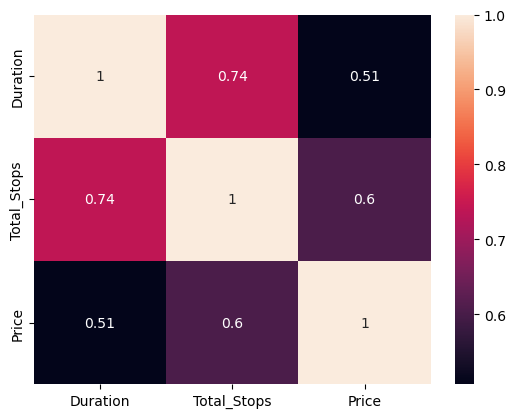

In [17]:
numeric_data = planes.select_dtypes("number")
sns.heatmap(numeric_data.corr(), annot=True)
plt.show()

In [18]:
planes["month"] = planes["Date_of_Journey"].dt.month
planes["weekday"] = planes["Date_of_Journey"].dt.weekday

planes[["month","weekday","Date_of_Journey"]].head(10)

,month,weekday,Date_of_Journey
0,3,6,2019-03-24
1,5,2,2019-05-01
2,6,6,2019-06-09
3,5,6,2019-05-12
4,3,4,2019-03-01
5,6,0,2019-06-24
6,3,1,2019-03-12
7,3,4,2019-03-01
8,3,1,2019-03-12
9,5,0,2019-05-27


In [19]:
planes["Dep_Hour"] = planes["Dep_Time"].dt.month
planes["Arrival_Hour"] = planes["Arrival_Time"].dt.weekday

In [20]:
planes.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,weekday,Dep_Hour,Arrival_Hour
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,2019-03-24 22:20:00,2019-03-24 01:10:00,170.0,0,No info,3897.0,3,6,3,6
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,2019-05-01 05:50:00,2019-05-01 13:15:00,445.0,2,No info,7662.0,5,2,5,2
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,2019-06-09 09:25:00,2019-06-09 04:25:00,1140.0,2,No info,13882.0,6,6,6,6
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,2019-05-12 18:05:00,2019-05-12 23:30:00,325.0,1,No info,6218.0,5,6,5,6
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,2019-03-01 16:50:00,2019-03-01 21:35:00,285.0,1,No info,13302.0,3,4,3,4


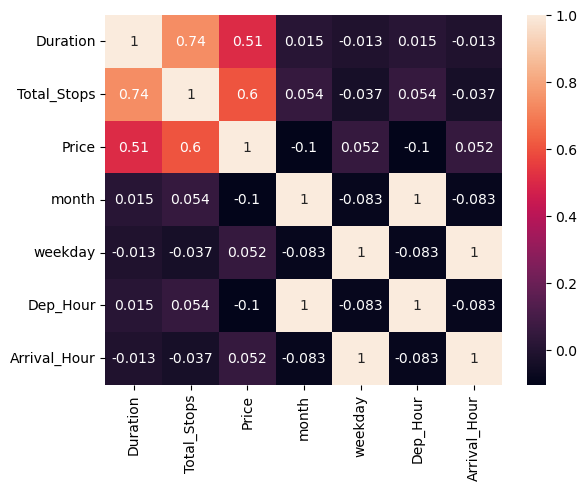

In [21]:
numeric_data = planes.select_dtypes("number")
sns.heatmap(numeric_data.corr(), annot=True)
plt.show()

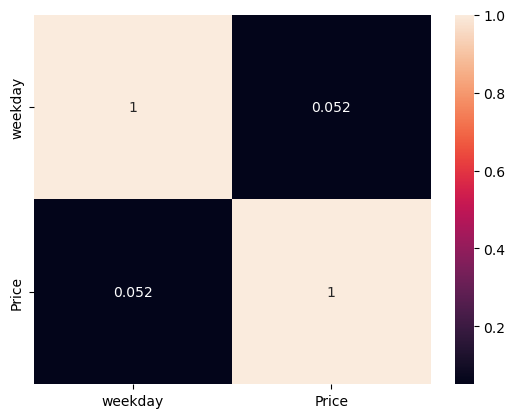

In [23]:
numeric_data = planes[["weekday","Price"]]
sns.heatmap(numeric_data.corr(), annot=True)
plt.show()

In [24]:
planes["Price"].describe()

count    10682.000000
mean      9087.214567
std       4611.548810
min       1759.000000
25%       5277.000000
50%       8372.000000
75%      12373.000000
max      79512.000000
Name: Price, dtype: float64

In [25]:
Q1 = planes["Price"].quantile(0.25)
Q2 = planes["Price"].median()
Q3 = planes["Price"].quantile(0.75)
max = planes["Price"].max()

labels = ["Economy", "Premium Economy", "Bussiness Class", "First Class"]
bins = [0,Q1,Q2,Q3,max]

planes["Price_catagory"] = pd.cut(planes["Price"],labels=labels, bins = bins)

In [27]:
planes.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,month,weekday,Dep_Hour,Arrival_Hour,Price_catagory
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,2019-03-24 22:20:00,2019-03-24 01:10:00,170.0,0,No info,3897.0,3,6,3,6,Economy
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,2019-05-01 05:50:00,2019-05-01 13:15:00,445.0,2,No info,7662.0,5,2,5,2,Premium Economy
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,2019-06-09 09:25:00,2019-06-09 04:25:00,1140.0,2,No info,13882.0,6,6,6,6,First Class
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,2019-05-12 18:05:00,2019-05-12 23:30:00,325.0,1,No info,6218.0,5,6,5,6,Premium Economy
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,2019-03-01 16:50:00,2019-03-01 21:35:00,285.0,1,No info,13302.0,3,4,3,4,First Class
